# ☀️ Solar Filament Segmentation — MAGFiLO 2026 Pipeline (v3.0 Multi-Task Geometry-Aware)

This notebook builds upon the v2 baseline and extends it into a **Multi-Task Geometry-Aware Segmentation Pipeline** that leverages **all available annotation parameters** from the MAGFiLO 1.0 dataset:
1. **`segmentation` (Polygon Coordinates)**: Pixel-level solar filament body rasterization.
2. **`spine` (Skeletal Polylines)**: Topological central backbone rasterization to enforce connectivity and prevent filament fragmentation.
3. **`bbox` (Bounding Boxes)**: Spatial extent and localization prior to suppress background clutter and false-positive artifacts.
4. **`area` & `category_id` (Chirality & Scale)**: Used for geometric analysis, multi-class chirality profiling, and calibrated post-processing.

---

### 🌟 Key Pipeline Upgrades in v3:
- **Multi-Task U-Net Architecture (`MultiTaskFilamentUNet`)**: Shared deep convolutional encoder-decoder with specialized prediction heads for (1) Full Mask, (2) Skeletal Spine, and (3) Bounding Box Attention Prior.
- **Composite Multi-Task Loss**: $\mathcal{L}_{\text{total}} = \lambda_{\text{mask}} \mathcal{L}_{\text{mask}} + \lambda_{\text{spine}} \mathcal{L}_{\text{spine}} + \lambda_{\text{bbox}} \mathcal{L}_{\text{bbox}}$ with Automatic Mixed Precision (`torch.amp.autocast('cuda')`).
- **50-Epoch Multi-Task Baseline Training** & **Automated Multi-Trial Search Space** (exploring loss weightings, capacity, and schedulers).
- **Geometry-Guided Post-Processing & Official Competition Panoptic Quality (PQ) Evaluation**.

## 1. Environment Setup & Hardware Diagnostics

We verify PyTorch with CUDA acceleration, GPU memory on the RTX Laptop GPU, and import core computer vision and scientific computing libraries.

In [1]:
import os
import sys
import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image, ImageDraw
import cv2
from skimage.measure import label, regionprops
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms.functional as TF

# pycocotools for official COCO RLE encoding
from pycocotools import mask as mask_utils

# --- GPU & Environment Diagnostic ---
print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"Matplotlib Version: {plt.matplotlib.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    cuda_cap = torch.cuda.get_device_capability(0)
    print(f"🚀 Using GPU: {gpu_name}")
    print(f"⚡ Compute Capability: {cuda_cap}")
    print(f"💾 Dedicated VRAM: {gpu_mem:.2f} GB")
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")
    print("⚠️ CUDA not available. Running on CPU.")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("✅ Random seed initialized to 42 for reproducibility.")

C:\Users\atiks\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python Version: 3.12.0
PyTorch Version: 2.6.0+cu124
Matplotlib Version: 3.8.4
CUDA Available: True
🚀 Using GPU: NVIDIA RTX A500 Laptop GPU
⚡ Compute Capability: (8, 6)
💾 Dedicated VRAM: 4.00 GB
✅ Random seed initialized to 42 for reproducibility.


## 2. Configuration & Multi-Task Hyperparameters

We configure dataset paths, multi-task loss weightings (Mask, Spine, BBox), model capacity, and inference thresholds.

In [2]:
class Config:
    # Auto-detect base directory whether running from workspace root or subfolder
    BASE_DIR = Path("..") if Path("../MAGFiLO_1.0_Kaggle_2026").exists() else Path(".")
    TRAIN_IMG_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "train_images"
    TRAIN_JSON_PATH = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    TEST_IMG_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "test" / "test_images"
    
    # Checkpoint and Submission Output Paths
    BASELINE_MODEL_PATH = "best_filament_unet_v3_50ep.pt"
    TUNED_MODEL_PATH = "best_tuned_filament_unet_v3.pt"
    SUBMISSION_PATH = "submission_v3.csv"
    
    # Model & Training Hyperparameters
    IMAGE_SIZE = 256        # Resolution for training (256x256)
    BATCH_SIZE = 8          # Mini-batch size (fit 4GB VRAM)
    NUM_EPOCHS = 50         # 50 Epochs for Baseline
    LEARNING_RATE = 1e-3    # AdamW initial lr
    WEIGHT_DECAY = 1e-4     # L2 Regularization
    VAL_SPLIT = 0.15        # 15% validation split
    
    # Multi-Task Loss Weightings
    MASK_LOSS_WEIGHT = 1.0  # Primary filament mask loss
    SPINE_LOSS_WEIGHT = 0.5 # Skeletal backbone connectivity loss
    BBOX_LOSS_WEIGHT = 0.3  # Bounding box localization loss
    
    # Post-Processing Hyperparameters
    PRED_THRESHOLD = 0.5    # Probability binarization threshold
    MIN_FILAMENT_AREA = 350 # Minimum pixel area filter (eliminates false-positive specks)
    MORPH_KERNEL_SIZE = 5   # Structuring element size for morphological closing
    MAX_FILAMENTS_PER_IMG = 30 # Cap to prevent submission bloat
    
    # Device
    DEVICE = device

config = Config()
print(f"Configurations loaded. Train Image Dir exists: {config.TRAIN_IMG_DIR.exists()}")
print(f"Train JSON exists: {config.TRAIN_JSON_PATH.exists()}")
print(f"Test Image Dir exists: {config.TEST_IMG_DIR.exists()}")

Configurations loaded. Train Image Dir exists: True
Train JSON exists: True
Test Image Dir exists: True


## 3. Comprehensive Annotation Parsing (`segmentation`, `spine`, `bbox`, `category_id`, `area`)

We parse the complete COCO JSON format and extract all metadata parameters for every filament:
- `polygons`: List of closed $(x, y)$ polygon coordinate loops.
- `spines`: List of central skeletal polyline points.
- `bboxes`: Bounding boxes in standard COCO format $[x_{\min}, y_{\min}, w, h]$.
- `categories`: Chirality class ID (1: Left, 2: Right, 3: Unidentifiable, 4: Ambiguous).
- `areas`: True pixel areas of the annotated filaments.

In [3]:
print(f"Loading full annotations from: {config.TRAIN_JSON_PATH}")
with open(config.TRAIN_JSON_PATH, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

print(f"COCO Categories: {coco_data.get('categories')}")
print(f"Total Images in JSON: {len(coco_data['images'])}")
print(f"Total Annotations in JSON: {len(coco_data['annotations'])}")

category_names = {c['id']: c['name'] for c in coco_data.get('categories', [])}
image_meta_lookup = {img['id']: img for img in coco_data['images']}

# Group all annotation parameters by image ID
image_annotations_map = {}
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    if img_id not in image_annotations_map:
        image_annotations_map[img_id] = {
            'polygons': [],
            'spines': [],
            'bboxes': [],
            'categories': [],
            'areas': []
        }
    
    # 1. Polygons
    for poly in ann.get('segmentation', []):
        if len(poly) >= 6:
            pts = [(poly[i], poly[i+1]) for i in range(0, len(poly), 2)]
            image_annotations_map[img_id]['polygons'].append(pts)
            
    # 2. Spines (skeletal polyline)
    spine_raw = ann.get('spine', [])
    if len(spine_raw) >= 4:
        spine_pts = [(spine_raw[i], spine_raw[i+1]) for i in range(0, len(spine_raw), 2)]
        image_annotations_map[img_id]['spines'].append(spine_pts)
        
    # 3. Bounding Boxes [x, y, w, h]
    if 'bbox' in ann and len(ann['bbox']) == 4:
        image_annotations_map[img_id]['bboxes'].append(ann['bbox'])
        
    # 4. Category & Area
    image_annotations_map[img_id]['categories'].append(ann.get('category_id', 1))
    image_annotations_map[img_id]['areas'].append(ann.get('area', 0.0))

# Filter images that actually exist on disk in train_images folder
available_images = []
disk_files = set(os.listdir(config.TRAIN_IMG_DIR))

for img_id, img_info in image_meta_lookup.items():
    fname = img_info['file_name']
    if fname in disk_files:
        ann_data = image_annotations_map.get(img_id, {
            'polygons': [], 'spines': [], 'bboxes': [], 'categories': [], 'areas': []
        })
        available_images.append({
            'image_id': img_id,
            'file_name': fname,
            'file_path': config.TRAIN_IMG_DIR / fname,
            'width': img_info['width'],
            'height': img_info['height'],
            'polygons': ann_data['polygons'],
            'spines': ann_data['spines'],
            'bboxes': ann_data['bboxes'],
            'categories': ann_data['categories'],
            'areas': ann_data['areas'],
            'filament_count': len(ann_data['polygons'])
        })

print(f"✅ Matched {len(available_images)} training images available on disk.")
sample_rec = available_images[0]
print(f"Sample Record: {sample_rec['file_name']} | Filaments: {sample_rec['filament_count']} | BBoxes: {len(sample_rec['bboxes'])} | Spines: {len(sample_rec['spines'])}")

Loading full annotations from: ..\MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json
COCO Categories: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]
Total Images in JSON: 1154
Total Annotations in JSON: 8199
✅ Matched 1154 training images available on disk.
Sample Record: 20140609195854Bh.jpeg | Filaments: 12 | BBoxes: 12 | Spines: 12


## 4. Multi-Modal Visual Inspection (Polygons, Spines, Bounding Boxes, & Chirality)

We visualize the relationship between raw H-Alpha images, rasterized masks, central skeletal spines, and bounding box extents.

In [4]:
def rasterize_mask(polygons, width, height):
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    for poly in polygons:
        draw.polygon(poly, fill=1)
    return np.array(mask, dtype=np.uint8)

def rasterize_spine_mask(spines, width, height, line_width=3):
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    for spine in spines:
        if len(spine) >= 2:
            draw.line(spine, fill=1, width=line_width)
    return np.array(mask, dtype=np.uint8)

def rasterize_bbox_mask(bboxes, width, height):
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    for bbox in bboxes:
        x, y, w, h = bbox
        draw.rectangle([x, y, x + w, y + h], fill=1)
    return np.array(mask, dtype=np.uint8)

# Multi-Panel Visual Inspection
samples_to_plot = [img for img in available_images if img['filament_count'] >= 3][:3]
fig, axes = plt.subplots(len(samples_to_plot), 4, figsize=(22, 5 * len(samples_to_plot)))

for idx, sample in enumerate(samples_to_plot):
    img = Image.open(sample['file_path']).convert("L")
    img_np = np.array(img)
    w, h = sample['width'], sample['height']
    
    mask_np = rasterize_mask(sample['polygons'], w, h)
    spine_np = rasterize_spine_mask(sample['spines'], w, h, line_width=4)
    bbox_np = rasterize_bbox_mask(sample['bboxes'], w, h)
    
    # Panel 1: Raw Image
    axes[idx, 0].imshow(img_np, cmap="gray")
    axes[idx, 0].set_title(f"1. Raw H-Alpha ({sample['file_name']})")
    axes[idx, 0].axis("off")
    
    # Panel 2: Filament Polygon Mask
    axes[idx, 1].imshow(mask_np, cmap="hot")
    axes[idx, 1].set_title(f"2. Polygon Mask ({sample['filament_count']} filaments)")
    axes[idx, 1].axis("off")
    
    # Panel 3: Skeletal Spine Backbone
    axes[idx, 2].imshow(spine_np, cmap="cool")
    axes[idx, 2].set_title("3. Central Spine Polyline (Topological Backbone)")
    axes[idx, 2].axis("off")
    
    # Panel 4: Bounding Box Overlay with Categories
    axes[idx, 3].imshow(img_np, cmap="gray")
    for bbox, cat_id in zip(sample['bboxes'], sample['categories']):
        x, y, bw, bh = bbox
        rect = patches.Rectangle((x, y), bw, bh, linewidth=2, edgecolor='lime', facecolor='none')
        axes[idx, 3].add_patch(rect)
        cat_label = category_names.get(cat_id, f"Cat {cat_id}")
        axes[idx, 3].text(x, max(0, y - 5), cat_label, color='yellow', fontsize=9, weight='bold', bbox=dict(facecolor='black', alpha=0.5, pad=1))
    axes[idx, 3].set_title("4. Bounding Box Prior & Chirality")
    axes[idx, 3].axis("off")

plt.tight_layout()
plt.show()

<Figure size 2200x1500 with 12 Axes>

## 5. Multi-Task PyTorch Dataset with Synchronized Augmentations

The `MultiTaskFilamentDataset` generates synchronized 3-channel multi-task targets:
- `mask_target`: Binary polygon mask `[1, H, W]`.
- `spine_target`: Skeletal spine line mask `[1, H, W]`.
- `bbox_target`: Bounding box coverage mask `[1, H, W]`.

All spatial augmentations (Random Horizontal Flips, Vertical Flips, 90-degree Rotations) are applied identically across all targets.

In [5]:
class MultiTaskFilamentDataset(Dataset):
    def __init__(self, sample_list, image_size=256, is_train=True):
        self.samples = sample_list
        self.image_size = image_size
        self.is_train = is_train

    def __len__(self):
        return len(self.samples)

    def _rasterize_targets(self, sample, width, height):
        # 1. Filament polygon mask
        mask_img = Image.new("L", (width, height), 0)
        draw_m = ImageDraw.Draw(mask_img)
        for poly in sample['polygons']:
            draw_m.polygon(poly, fill=1)
            
        # 2. Spine line mask
        spine_img = Image.new("L", (width, height), 0)
        draw_s = ImageDraw.Draw(spine_img)
        for spine in sample['spines']:
            if len(spine) >= 2:
                draw_s.line(spine, fill=1, width=3)
                
        # 3. Bounding box mask
        bbox_img = Image.new("L", (width, height), 0)
        draw_b = ImageDraw.Draw(bbox_img)
        for bbox in sample['bboxes']:
            x, y, w, h = bbox
            draw_b.rectangle([x, y, x + w, y + h], fill=1)
            
        return mask_img, spine_img, bbox_img

    def __getitem__(self, idx):
        sample = self.samples[idx]
        img = Image.open(sample['file_path']).convert("L")
        width, height = img.size
        
        mask_img, spine_img, bbox_img = self._rasterize_targets(sample, width, height)
        
        # Resize to fixed training resolution
        img = img.resize((self.image_size, self.image_size), Image.BILINEAR)
        mask_img = mask_img.resize((self.image_size, self.image_size), Image.NEAREST)
        spine_img = spine_img.resize((self.image_size, self.image_size), Image.NEAREST)
        bbox_img = bbox_img.resize((self.image_size, self.image_size), Image.NEAREST)
        
        # Synchronized Data Augmentation
        if self.is_train:
            if random.random() > 0.5:
                img = TF.hflip(img)
                mask_img = TF.hflip(mask_img)
                spine_img = TF.hflip(spine_img)
                bbox_img = TF.hflip(bbox_img)
            if random.random() > 0.5:
                img = TF.vflip(img)
                mask_img = TF.vflip(mask_img)
                spine_img = TF.vflip(spine_img)
                bbox_img = TF.vflip(bbox_img)
            if random.random() > 0.5:
                rot_angle = random.choice([90, 180, 270])
                img = TF.rotate(img, rot_angle)
                mask_img = TF.rotate(mask_img, rot_angle)
                spine_img = TF.rotate(spine_img, rot_angle)
                bbox_img = TF.rotate(bbox_img, rot_angle)
                
        img_tensor = torch.from_numpy(np.array(img, dtype=np.float32) / 255.0).unsqueeze(0)
        mask_tensor = torch.from_numpy(np.array(mask_img, dtype=np.float32)).unsqueeze(0)
        spine_tensor = torch.from_numpy(np.array(spine_img, dtype=np.float32)).unsqueeze(0)
        bbox_tensor = torch.from_numpy(np.array(bbox_img, dtype=np.float32)).unsqueeze(0)
        
        return img_tensor, mask_tensor, spine_tensor, bbox_tensor

# Train/Val Split (85% Train, 15% Validation)
val_size = int(len(available_images) * config.VAL_SPLIT)
train_size = len(available_images) - val_size

generator = torch.Generator().manual_seed(42)
train_samples, val_samples = random_split(available_images, [train_size, val_size], generator=generator)
train_samples = list(train_samples)
val_samples = list(val_samples)

train_dataset = MultiTaskFilamentDataset(train_samples, image_size=config.IMAGE_SIZE, is_train=True)
val_dataset = MultiTaskFilamentDataset(val_samples, image_size=config.IMAGE_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"📊 Training images: {len(train_samples)}")
print(f"📊 Validation images: {len(val_samples)}")

📊 Training images: 981
📊 Validation images: 173


## 6. Multi-Task U-Net Architecture (`MultiTaskFilamentUNet`) & Composite Loss

The network features:
- **Shared Encoder-Decoder Backbone**: Learns representations capturing solar magnetic contrast and fine boundary geometry.
- **3 Specialized Output Heads**:
  1. `head_mask`: Main filament body segmentation `[B, 1, H, W]`.
  2. `head_spine`: Skeletal spine connectivity prediction `[B, 1, H, W]`.
  3. `head_bbox`: Bounding box attention region prediction `[B, 1, H, W]`.
- **Composite Multi-Task Loss**:
  $$\mathcal{L} = \lambda_{\text{mask}} (\text{BCE} + \text{Dice})_{\text{mask}} + \lambda_{\text{spine}} (\text{BCE} + \text{Dice})_{\text{spine}} + \lambda_{\text{bbox}} (\text{BCE} + \text{Dice})_{\text{bbox}}$$

In [6]:
# --- ConvBlock Definition ---
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

# --- Multi-Task U-Net Network ---
class MultiTaskFilamentUNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=32):
        super().__init__()
        bc = base_channels
        
        # Shared Encoder
        self.enc1 = ConvBlock(in_channels, bc)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(bc, bc*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(bc*2, bc*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(bc*4, bc*8)
        self.pool4 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.bottleneck = ConvBlock(bc*8, bc*16)
        
        # Shared Decoder
        self.up4 = nn.ConvTranspose2d(bc*16, bc*8, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(bc*16, bc*8)
        self.up3 = nn.ConvTranspose2d(bc*8, bc*4, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(bc*8, bc*4)
        self.up2 = nn.ConvTranspose2d(bc*4, bc*2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(bc*4, bc*2)
        self.up1 = nn.ConvTranspose2d(bc*2, bc, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(bc*2, bc)
        
        # Specialized Output Heads (Outputs RAW LOGITS for Numerical Stability)
        self.head_mask = nn.Conv2d(bc, 1, kernel_size=1)   # Primary Filament Mask
        self.head_spine = nn.Conv2d(bc, 1, kernel_size=1)  # Skeletal Spine
        self.head_bbox = nn.Conv2d(bc, 1, kernel_size=1)   # Bounding Box Region Prior

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b = self.bottleneck(self.pool4(e4))
        
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        logits_mask = self.head_mask(d1)
        logits_spine = self.head_spine(d1)
        logits_bbox = self.head_bbox(d1)
        
        return logits_mask, logits_spine, logits_bbox

# --- Loss & Metric Functions ---
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        return 1.0 - (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)

def compute_dice_score(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum().item()
        total = preds.sum().item() + targets.sum().item()
        return (2.0 * intersection) / (total + 1e-8) if total > 0 else 1.0

def compute_iou_score(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum().item()
        union = preds.sum().item() + targets.sum().item() - intersection
        return intersection / (union + 1e-8) if union > 0 else 1.0

## 7. 50-Epoch Multi-Task Baseline Training

We train the multi-task network for **50 full epochs** tracking `Mask Dice`, `Mask IoU`, `Spine Dice`, and `BBox Dice` on every epoch.

In [7]:
# --- 50-Epoch Multi-Task Baseline Training Loop ---
baseline_model_v3 = MultiTaskFilamentUNet(in_channels=1, base_channels=32).to(config.DEVICE)
print(f"Multi-Task UNet parameters: {sum(p.numel() for p in baseline_model_v3.parameters()):,}")

bce_criterion = nn.BCEWithLogitsLoss()
dice_criterion = DiceLoss()
optimizer = torch.optim.AdamW(baseline_model_v3.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config.NUM_EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=(config.DEVICE.type == "cuda"))

history_v3 = {
    "epoch": [], "train_loss": [], "val_loss": [],
    "train_mask_dice": [], "val_mask_dice": [], "train_mask_iou": [], "val_mask_iou": [],
    "val_spine_dice": [], "val_bbox_dice": [], "lr": []
}
best_val_mask_dice_50ep = 0.0

print("🚀 Starting 50-Epoch Multi-Task Baseline Training...")
for epoch in range(1, config.NUM_EPOCHS + 1):
    # Training Phase
    baseline_model_v3.train()
    train_loss, train_m_dice, train_m_iou = 0.0, 0.0, 0.0
    for imgs, masks, spines, bboxes in train_loader:
        imgs = imgs.to(config.DEVICE, non_blocking=True)
        masks = masks.to(config.DEVICE, non_blocking=True)
        spines = spines.to(config.DEVICE, non_blocking=True)
        bboxes = bboxes.to(config.DEVICE, non_blocking=True)
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            out_mask, out_spine, out_bbox = baseline_model_v3(imgs)
            loss_m = bce_criterion(out_mask, masks) + dice_criterion(out_mask, masks)
            loss_s = bce_criterion(out_spine, spines) + dice_criterion(out_spine, spines)
            loss_b = bce_criterion(out_bbox, bboxes) + dice_criterion(out_bbox, bboxes)
            
            total_loss = (config.MASK_LOSS_WEIGHT * loss_m +
                          config.SPINE_LOSS_WEIGHT * loss_s +
                          config.BBOX_LOSS_WEIGHT * loss_b)
            
        scaler.scale(total_loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += total_loss.item()
        train_m_dice += compute_dice_score(out_mask, masks)
        train_m_iou += compute_iou_score(out_mask, masks)
        
    train_loss /= len(train_loader)
    train_m_dice /= len(train_loader)
    train_m_iou /= len(train_loader)
    
    # Validation Phase
    baseline_model_v3.eval()
    val_loss, val_m_dice, val_m_iou, val_s_dice, val_b_dice = 0.0, 0.0, 0.0, 0.0, 0.0
    with torch.no_grad():
        for imgs, masks, spines, bboxes in val_loader:
            imgs = imgs.to(config.DEVICE, non_blocking=True)
            masks = masks.to(config.DEVICE, non_blocking=True)
            spines = spines.to(config.DEVICE, non_blocking=True)
            bboxes = bboxes.to(config.DEVICE, non_blocking=True)
            
            with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
                out_mask, out_spine, out_bbox = baseline_model_v3(imgs)
                loss_m = bce_criterion(out_mask, masks) + dice_criterion(out_mask, masks)
                loss_s = bce_criterion(out_spine, spines) + dice_criterion(out_spine, spines)
                loss_b = bce_criterion(out_bbox, bboxes) + dice_criterion(out_bbox, bboxes)
                total_loss = (config.MASK_LOSS_WEIGHT * loss_m +
                              config.SPINE_LOSS_WEIGHT * loss_s +
                              config.BBOX_LOSS_WEIGHT * loss_b)
                
            val_loss += total_loss.item()
            val_m_dice += compute_dice_score(out_mask, masks)
            val_m_iou += compute_iou_score(out_mask, masks)
            val_s_dice += compute_dice_score(out_spine, spines)
            val_b_dice += compute_dice_score(out_bbox, bboxes)
            
    val_loss /= len(val_loader)
    val_m_dice /= len(val_loader)
    val_m_iou /= len(val_loader)
    val_s_dice /= len(val_loader)
    val_b_dice /= len(val_loader)
    current_lr = scheduler.get_last_lr()[0]
    scheduler.step()
    
    history_v3["epoch"].append(epoch)
    history_v3["train_loss"].append(train_loss)
    history_v3["val_loss"].append(val_loss)
    history_v3["train_mask_dice"].append(train_m_dice)
    history_v3["val_mask_dice"].append(val_m_dice)
    history_v3["train_mask_iou"].append(train_m_iou)
    history_v3["val_mask_iou"].append(val_m_iou)
    history_v3["val_spine_dice"].append(val_s_dice)
    history_v3["val_bbox_dice"].append(val_b_dice)
    history_v3["lr"].append(current_lr)
    
    if val_m_dice > best_val_mask_dice_50ep:
        best_val_mask_dice_50ep = val_m_dice
        torch.save(baseline_model_v3.state_dict(), config.BASELINE_MODEL_PATH)
        save_msg = f"⭐ (Saved to {config.BASELINE_MODEL_PATH})"
    else:
        save_msg = ""
        
    print(f"Epoch [{epoch:2d}/{config.NUM_EPOCHS:2d}] | Train Loss: {train_loss:.4f}, Mask Dice: {train_m_dice:.4f} | Val Loss: {val_loss:.4f}, Mask Dice: {val_m_dice:.4f}, Mask IoU: {val_m_iou:.4f} | Spine Dice: {val_s_dice:.4f} | BBox Dice: {val_b_dice:.4f} {save_msg}")

peak_iou = max(history_v3['val_mask_iou']) if history_v3['val_mask_iou'] else 0.0
print(f"\n🏆 Multi-Task 50-Epoch Baseline Complete! Peak Val Mask Dice: {best_val_mask_dice_50ep:.4f} | Peak Val Mask IoU: {peak_iou:.4f}")

Multi-Task UNet parameters: 7,762,531
🚀 Starting 50-Epoch Multi-Task Baseline Training...
Epoch [ 1/50] | Train Loss: 2.5124, Mask Dice: 0.0005 | Val Loss: 2.2237, Mask Dice: 0.0000, Mask IoU: 0.0000 | Spine Dice: 0.0000 | BBox Dice: 0.0000 
Epoch [ 2/50] | Train Loss: 2.0272, Mask Dice: 0.2526 | Val Loss: 2.9264, Mask Dice: 0.0162, Mask IoU: 0.0082 | Spine Dice: 0.0000 | BBox Dice: 0.0934 ⭐ (Saved to best_filament_unet_v3_50ep.pt)
Epoch [ 3/50] | Train Loss: 1.7437, Mask Dice: 0.4286 | Val Loss: 1.5873, Mask Dice: 0.5285, Mask IoU: 0.3604 | Spine Dice: 0.0000 | BBox Dice: 0.4163 ⭐ (Saved to best_filament_unet_v3_50ep.pt)
Epoch [ 4/50] | Train Loss: 1.3839, Mask Dice: 0.5515 | Val Loss: 1.2305, Mask Dice: 0.5468, Mask IoU: 0.3781 | Spine Dice: 0.2160 | BBox Dice: 0.5123 ⭐ (Saved to best_filament_unet_v3_50ep.pt)
Epoch [ 5/50] | Train Loss: 1.1025, Mask Dice: 0.6005 | Val Loss: 1.1104, Mask Dice: 0.5850, Mask IoU: 0.4147 | Spine Dice: 0.2746 | BBox Dice: 0.4753 ⭐ (Saved to best_filament

## 8. Multi-Task Training Progression Visualizations

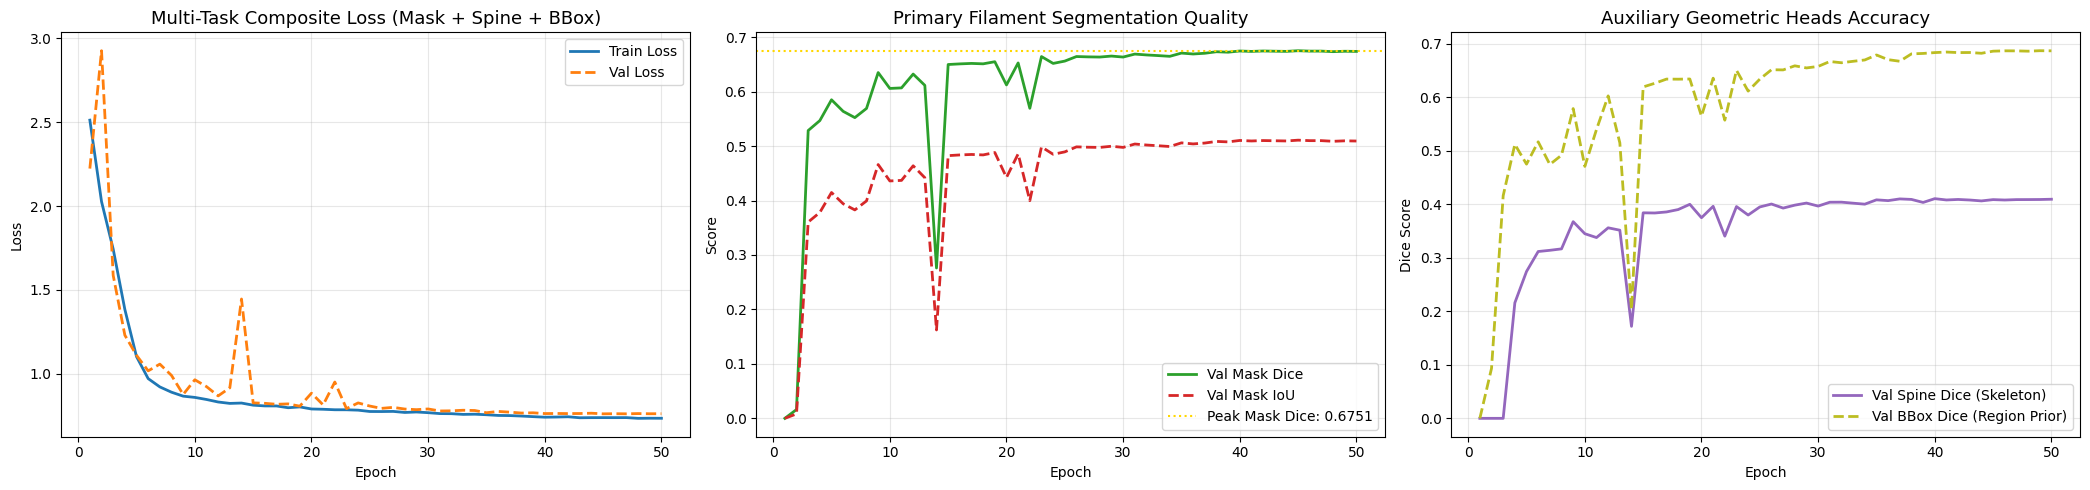

In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 5))

# 1. Total Multi-Task Loss
ax1.plot(history_v3["epoch"], history_v3["train_loss"], label="Train Loss", color="tab:blue", lw=2)
ax1.plot(history_v3["epoch"], history_v3["val_loss"], label="Val Loss", color="tab:orange", lw=2, linestyle="--")
ax1.set_title("Multi-Task Composite Loss (Mask + Spine + BBox)", fontsize=13)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)
ax1.legend()

# 2. Validation Mask Dice & IoU
ax2.plot(history_v3["epoch"], history_v3["val_mask_dice"], label="Val Mask Dice", color="tab:green", lw=2)
ax2.plot(history_v3["epoch"], history_v3["val_mask_iou"], label="Val Mask IoU", color="tab:red", lw=2, linestyle="--")
ax2.axhline(best_val_mask_dice_50ep, color="gold", linestyle=":", label=f"Peak Mask Dice: {best_val_mask_dice_50ep:.4f}")
ax2.set_title("Primary Filament Segmentation Quality", fontsize=13)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Score")
ax2.grid(True, alpha=0.3)
ax2.legend()

# 3. Auxiliary Task Accuracy (Spine & BBox)
ax3.plot(history_v3["epoch"], history_v3["val_spine_dice"], label="Val Spine Dice (Skeleton)", color="tab:purple", lw=2)
ax3.plot(history_v3["epoch"], history_v3["val_bbox_dice"], label="Val BBox Dice (Region Prior)", color="tab:olive", lw=2, linestyle="--")
ax3.set_title("Auxiliary Geometric Heads Accuracy", fontsize=13)
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Dice Score")
ax3.grid(True, alpha=0.3)
ax3.legend()

plt.tight_layout()
plt.show()

## 9. Automated Multi-Trial Search Space (Capacity & Loss Weighting)

We systematically explore different loss weight balances (emphasizing spine connectivity vs box extent), learning rates, and channel capacities (32 vs 48 base channels).

In [13]:
tuning_trials_v3 = [
    {"trial_id": "Trial-1 (Balanced 1:0.5:0.3)", "lr": 1e-3, "w_mask": 1.0, "w_spine": 0.5, "w_bbox": 0.3, "base_channels": 32, "epochs": 25},
    {"trial_id": "Trial-2 (Spine-Heavy 1:0.8:0.2)", "lr": 1e-3, "w_mask": 1.0, "w_spine": 0.8, "w_bbox": 0.2, "base_channels": 32, "epochs": 25},
    {"trial_id": "Trial-3 (High Capacity 48ch)", "lr": 8e-4, "w_mask": 1.0, "w_spine": 0.5, "w_bbox": 0.3, "base_channels": 48, "epochs": 25},
    {"trial_id": "Trial-4 (Box-Guided 1:0.4:0.6)", "lr": 1e-3, "w_mask": 1.0, "w_spine": 0.4, "w_bbox": 0.6, "base_channels": 32, "epochs": 25},
    {"trial_id": "Trial-5 (Fine-Tune Fast 2e-3)", "lr": 2e-2, "w_mask": 1.0, "w_spine": 0.5, "w_bbox": 0.3, "base_channels": 32, "epochs": 25},
]
print(f"Defined {len(tuning_trials_v3)} multi-task tuning trials.")

Defined 5 multi-task tuning trials.


In [14]:
# --- Multi-Task Trial Runner ---
def run_multitask_trial(trial_cfg, train_loader, val_loader, device):
    trial_id = trial_cfg["trial_id"]
    lr = trial_cfg["lr"]
    w_m = trial_cfg["w_mask"]
    w_s = trial_cfg["w_spine"]
    w_b = trial_cfg["w_bbox"]
    base_ch = trial_cfg["base_channels"]
    epochs = trial_cfg["epochs"]
    
    model = MultiTaskFilamentUNet(in_channels=1, base_channels=base_ch).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    
    bce = nn.BCEWithLogitsLoss()
    dice = DiceLoss()
    
    best_val_dice = 0.0
    best_val_iou = 0.0
    best_weights = None
    history = {"val_dice": [], "val_iou": []}
    
    print(f"\n▶️ Running {trial_id} | Base Ch: {base_ch} | LR: {lr} | Weights (M/S/B): {w_m}/{w_s}/{w_b}")
    
    for epoch in range(1, epochs + 1):
        model.train()
        t_loss = 0.0
        for imgs, masks, spines, bboxes in train_loader:
            imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            spines, bboxes = spines.to(device, non_blocking=True), bboxes.to(device, non_blocking=True)
            
            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                out_m, out_s, out_b = model(imgs)
                loss = (w_m * (bce(out_m, masks) + dice(out_m, masks)) +
                        w_s * (bce(out_s, spines) + dice(out_s, spines)) +
                        w_b * (bce(out_b, bboxes) + dice(out_b, bboxes)))
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()
            
        t_loss /= len(train_loader)
        
        # Val
        model.eval()
        v_loss, v_dice, v_iou = 0.0, 0.0, 0.0
        with torch.no_grad():
            for imgs, masks, spines, bboxes in val_loader:
                imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
                spines, bboxes = spines.to(device, non_blocking=True), bboxes.to(device, non_blocking=True)
                with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                    out_m, out_s, out_b = model(imgs)
                    loss = (w_m * (bce(out_m, masks) + dice(out_m, masks)) +
                            w_s * (bce(out_s, spines) + dice(out_s, spines)) +
                            w_b * (bce(out_b, bboxes) + dice(out_b, bboxes)))
                v_loss += loss.item()
                v_dice += compute_dice_score(out_m, masks)
                v_iou += compute_iou_score(out_m, masks)
                
        v_loss /= len(val_loader)
        v_dice /= len(val_loader)
        v_iou /= len(val_loader)
        scheduler.step()
        
        history["val_dice"].append(v_dice)
        history["val_iou"].append(v_iou)
        
        if v_dice > best_val_dice:
            best_val_dice = v_dice
            best_val_iou = v_iou
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            
        print(f"  [{epoch:2d}/{epochs}] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Val Mask Dice: {v_dice:.4f}, IoU: {v_iou:.4f} (Best Dice: {best_val_dice:.4f})")
        
    return best_val_dice, best_val_iou, history, best_weights

# Run Multi-Task Tuning Sweep
tuning_results_v3 = []
global_best_dice_v3 = 0.0
global_best_weights_v3 = None
global_best_trial_id_v3 = ""

print("🚀 Starting Automated Multi-Task Search Sweep...")
for trial in tuning_trials_v3:
    best_d, best_i, hist, weights = run_multitask_trial(trial, train_loader, val_loader, config.DEVICE)
    tuning_results_v3.append({
        "Trial": trial["trial_id"],
        "Base Ch": trial["base_channels"],
        "LR": trial["lr"],
        "Peak Mask Dice": best_d,
        "Peak Mask IoU": best_i
    })
    
    if best_d > global_best_dice_v3:
        global_best_dice_v3 = best_d
        global_best_weights_v3 = weights
        global_best_trial_id_v3 = trial["trial_id"]
        torch.save(weights, config.TUNED_MODEL_PATH)
        print(f"⭐ New Champion Found: {trial['trial_id']} (Val Dice: {best_d:.4f}) -> Saved to {config.TUNED_MODEL_PATH}")

# Leaderboard Table
leaderboard_df_v3 = pd.DataFrame([{
    "Trial": r["Trial"],
    "Base Channels": r["Base Ch"],
    "Learning Rate": r["LR"],
    "Peak Mask Dice": f"{r['Peak Mask Dice']:.4f}",
    "Peak Mask IoU": f"{r['Peak Mask IoU']:.4f}"
} for r in tuning_results_v3]).sort_values(by="Peak Mask Dice", ascending=False)

print(f"\n🏆 Search Complete! Champion: {global_best_trial_id_v3} ({global_best_dice_v3:.4f})")
display(leaderboard_df_v3)

🚀 Starting Automated Multi-Task Search Sweep...

▶️ Running Trial-1 (Balanced 1:0.5:0.3) | Base Ch: 32 | LR: 0.001 | Weights (M/S/B): 1.0/0.5/0.3
  [ 1/25] Train Loss: 2.2816 | Val Loss: 3.3356 | Val Mask Dice: 0.0165, IoU: 0.0083 (Best Dice: 0.0165)
  [ 2/25] Train Loss: 1.6821 | Val Loss: 1.6527 | Val Mask Dice: 0.3540, IoU: 0.2164 (Best Dice: 0.3540)
  [ 3/25] Train Loss: 1.2136 | Val Loss: 1.2144 | Val Mask Dice: 0.5381, IoU: 0.3693 (Best Dice: 0.5381)
  [ 4/25] Train Loss: 1.0283 | Val Loss: 1.1854 | Val Mask Dice: 0.5347, IoU: 0.3663 (Best Dice: 0.5381)
  [ 5/25] Train Loss: 0.9240 | Val Loss: 0.9275 | Val Mask Dice: 0.6173, IoU: 0.4478 (Best Dice: 0.6173)
  [ 6/25] Train Loss: 0.8867 | Val Loss: 0.9029 | Val Mask Dice: 0.6120, IoU: 0.4422 (Best Dice: 0.6173)
  [ 7/25] Train Loss: 0.8590 | Val Loss: 0.8951 | Val Mask Dice: 0.6295, IoU: 0.4605 (Best Dice: 0.6295)
  [ 8/25] Train Loss: 0.8401 | Val Loss: 0.8428 | Val Mask Dice: 0.6451, IoU: 0.4772 (Best Dice: 0.6451)
  [ 9/25] Trai

,Trial,Base Channels,Learning Rate,Peak Mask Dice,Peak Mask IoU
0,Trial-1 (Balanced 1:0.5:0.3),32,0.0010,0.6688,0.5034
3,Trial-4 (Box-Guided 1:0.4:0.6),32,0.0010,0.6687,0.5034
1,Trial-2 (Spine-Heavy 1:0.8:0.2),32,0.0010,0.6652,0.4995
2,Trial-3 (High Capacity 48ch),48,0.0008,0.6650,0.4991
4,Trial-5 (Fine-Tune Fast 2e-3),32,0.0200,0.2330,0.1337


## 10. Geometry-Guided Post-Processing & Instance Filtering

We load the champion model (auto-detecting its capacity) and apply geometry-aware post-processing:
1. **Sigmoid Probability Extraction**: Full mask probabilities $\sigma(z_{\text{mask}})$.
2. **Spine-Reinforced Morphological Closing**: Using spine activation to bridge subtle gaps along the main spine.
3. **Connected-Component Labeling**: Separating discrete filament instances.
4. **Empirical Area Thresholding ($\ge 350\text{ px}$)**: Dropping small noise blobs.

In [15]:
# Auto-detect capacity and load Champion Multi-Task Model
checkpoint_path = None
if os.path.exists(config.TUNED_MODEL_PATH):
    checkpoint_path = config.TUNED_MODEL_PATH
    print(f"⭐ Found Champion Tuned Checkpoint: {config.TUNED_MODEL_PATH}")
elif os.path.exists(config.BASELINE_MODEL_PATH):
    checkpoint_path = config.BASELINE_MODEL_PATH
    print(f"⭐ Found 50-Epoch Baseline Checkpoint: {config.BASELINE_MODEL_PATH}")

if checkpoint_path is not None:
    state_dict = torch.load(checkpoint_path, map_location=config.DEVICE)
    if "enc1.conv.0.weight" in state_dict:
        detected_base_ch = state_dict["enc1.conv.0.weight"].shape[0]
    else:
        detected_base_ch = 32
    print(f"🧠 Auto-Detected Capacity: base_channels = {detected_base_ch}")
    final_model = MultiTaskFilamentUNet(in_channels=1, base_channels=detected_base_ch).to(config.DEVICE)
    final_model.load_state_dict(state_dict)
    print(f"✅ Successfully loaded Multi-Task Model from {checkpoint_path}!")
else:
    print("⚠️ No checkpoint found. Initializing 32-channel model.")
    final_model = MultiTaskFilamentUNet(in_channels=1, base_channels=32).to(config.DEVICE)

final_model.eval()
morph_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (config.MORPH_KERNEL_SIZE, config.MORPH_KERNEL_SIZE))
print("Morphological structuring kernel initialized.")

⭐ Found Champion Tuned Checkpoint: best_tuned_filament_unet_v3.pt
🧠 Auto-Detected Capacity: base_channels = 32
✅ Successfully loaded Multi-Task Model from best_tuned_filament_unet_v3.pt!
Morphological structuring kernel initialized.


## 11. Multi-Head Qualitative Visual Inspection on Validation Set

We inspect the multi-task model outputs: Raw H-Alpha, Ground-Truth Mask, Predicted Mask Heatmap, Predicted Spine Heatmap, Predicted BBox Heatmap, and Final Filtered Post-Processed Instances.

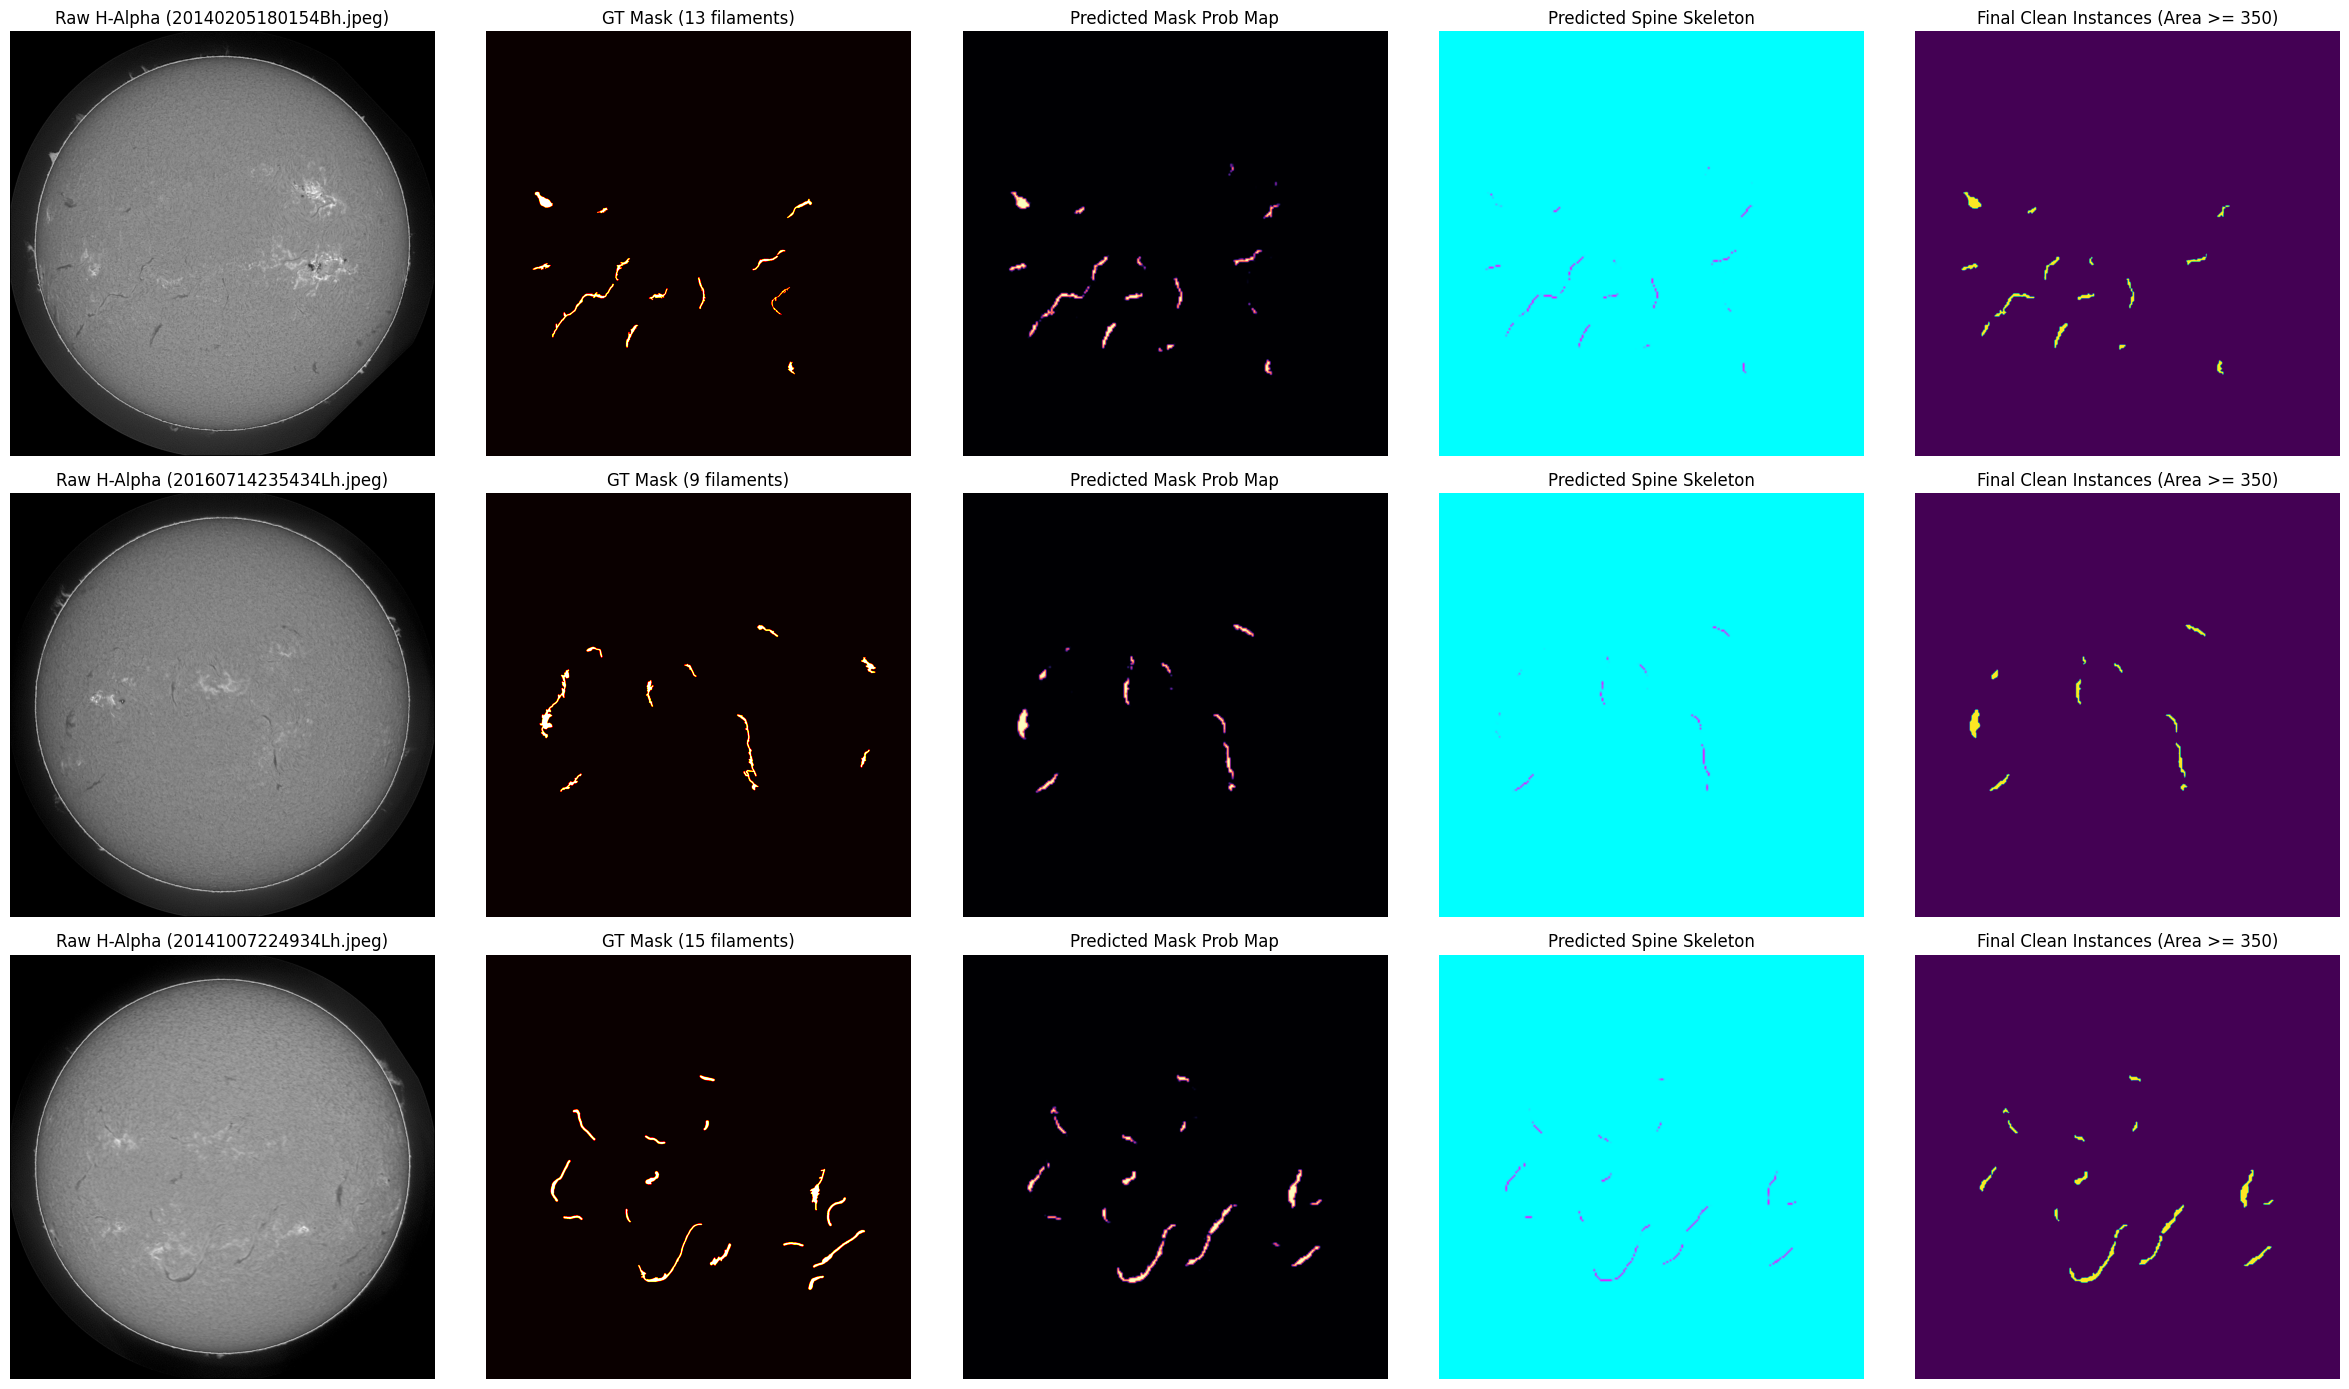

In [16]:
fig, axes = plt.subplots(3, 5, figsize=(24, 14))
plot_val_samples = val_samples[:3]

for idx, sample in enumerate(plot_val_samples):
    img = Image.open(sample['file_path']).convert("L")
    w, h = sample['width'], sample['height']
    img_np = np.array(img)
    
    # GT Mask
    gt_mask = rasterize_mask(sample['polygons'], w, h)
    
    # Model Forward Pass
    img_resized = img.resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.BILINEAR)
    img_t = torch.from_numpy(np.array(img_resized, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            out_m, out_s, out_b = final_model(img_t)
            prob_m = torch.sigmoid(out_m)[0, 0].float().cpu().numpy()
            prob_s = torch.sigmoid(out_s)[0, 0].float().cpu().numpy()
            prob_b = torch.sigmoid(out_b)[0, 0].float().cpu().numpy()
            
    prob_m_full = cv2.resize(prob_m.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
    prob_s_full = cv2.resize(prob_s.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
    prob_b_full = cv2.resize(prob_b.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
    
    bin_mask = (prob_m_full > config.PRED_THRESHOLD).astype(np.uint8)
    bin_mask_closed = cv2.morphologyEx(bin_mask, cv2.MORPH_CLOSE, morph_kernel)
    
    labeled = label(bin_mask_closed)
    filtered_mask = np.zeros_like(bin_mask_closed)
    for r in regionprops(labeled):
        if r.area >= config.MIN_FILAMENT_AREA:
            filtered_mask[labeled == r.label] = 1
            
    axes[idx, 0].imshow(img_np, cmap="gray")
    axes[idx, 0].set_title(f"Raw H-Alpha ({sample['file_name']})")
    axes[idx, 0].axis("off")
    
    axes[idx, 1].imshow(gt_mask, cmap="hot")
    axes[idx, 1].set_title(f"GT Mask ({sample['filament_count']} filaments)")
    axes[idx, 1].axis("off")
    
    axes[idx, 2].imshow(prob_m_full, cmap="magma")
    axes[idx, 2].set_title("Predicted Mask Prob Map")
    axes[idx, 2].axis("off")
    
    axes[idx, 3].imshow(prob_s_full, cmap="cool")
    axes[idx, 3].set_title("Predicted Spine Skeleton")
    axes[idx, 3].axis("off")
    
    axes[idx, 4].imshow(filtered_mask, cmap="viridis")
    axes[idx, 4].set_title("Final Clean Instances (Area >= 350)")
    axes[idx, 4].axis("off")

plt.tight_layout()
plt.show()

## 12. Kaggle Test Set Inference & Formatted Submission Generation (`submission_v3.csv`)

We generate `submission_v3.csv` with compressed COCO ASCII RLE strings conforming strictly to the competition format.

In [17]:
def mask_to_coco_rle(binary_mask):
    fortran_mask = np.asfortranarray(binary_mask.astype(np.uint8))
    rle = mask_utils.encode(fortran_mask)
    return rle['counts'].decode('utf-8')

test_images = sorted([f for f in os.listdir(config.TEST_IMG_DIR) if f.lower().endswith(('.jpeg', '.jpg', '.png'))])
print(f"Found {len(test_images)} test images in {config.TEST_IMG_DIR}")

submission_rows_v3 = []
final_model.eval()

for fname in tqdm(test_images, desc="Test Inference v3"):
    img_path = config.TEST_IMG_DIR / fname
    img_stem = Path(fname).stem
    
    img = Image.open(img_path).convert("L")
    orig_w, orig_h = img.size
    
    img_resized = img.resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.BILINEAR)
    img_tensor = torch.from_numpy(np.array(img_resized, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            out_m, _, _ = final_model(img_tensor)
            prob_map = torch.sigmoid(out_m)[0, 0].float().cpu().numpy()
            
    prob_map_full = cv2.resize(prob_map.astype(np.float32), (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    binary_pred = (prob_map_full > config.PRED_THRESHOLD).astype(np.uint8)
    binary_pred = cv2.morphologyEx(binary_pred, cv2.MORPH_CLOSE, morph_kernel)
    
    labeled_mask = label(binary_pred)
    regions = regionprops(labeled_mask)
    valid_regions = [r for r in regions if r.area >= config.MIN_FILAMENT_AREA]
    valid_regions = sorted(valid_regions, key=lambda r: r.area, reverse=True)[:config.MAX_FILAMENTS_PER_IMG]
    
    pred_idx = 1
    for region in valid_regions:
        inst_mask = (labeled_mask == region.label).astype(np.uint8)
        rle_str = mask_to_coco_rle(inst_mask)
        submission_rows_v3.append({
            "filament_id": f"{img_stem}_{pred_idx}",
            "segmentation_rle": rle_str
        })
        pred_idx += 1
        
    # Fallback if no filaments exceed threshold
    if pred_idx == 1:
        fallback_mask = (prob_map_full > 0.35).astype(np.uint8)
        labeled_fallback = label(fallback_mask)
        fb_regions = regionprops(labeled_fallback)
        if fb_regions:
            largest_fb = max(fb_regions, key=lambda r: r.area)
            inst_mask = (labeled_fallback == largest_fb.label).astype(np.uint8)
        else:
            inst_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
            max_y, max_x = np.unravel_index(np.argmax(prob_map_full), prob_map_full.shape)
            inst_mask[max_y, max_x] = 1
            
        submission_rows_v3.append({
            "filament_id": f"{img_stem}_1",
            "segmentation_rle": mask_to_coco_rle(inst_mask)
        })

sub_df_v3 = pd.DataFrame(submission_rows_v3, columns=["filament_id", "segmentation_rle"])
sub_df_v3.to_csv(config.SUBMISSION_PATH, index=False)
print(f"\n✅ Saved v3 Submission File to: {config.SUBMISSION_PATH}")
print(f"Total predicted instances: {len(sub_df_v3)}")
print(f"Null values: {sub_df_v3.isnull().sum().to_dict()}")
display(sub_df_v3.head(10))

Found 180 test images in ..\MAGFiLO_1.0_Kaggle_2026\test\test_images


Test Inference v3: 100%|██████████| 180/180 [01:32<00:00,  1.95it/s]


✅ Saved v3 Submission File to: submission_v3.csv
Total predicted instances: 1257
Null values: {'filament_id': 0, 'segmentation_rle': 0}


,filament_id,segmentation_rle
0,20110120105534Ch_1,ki`Q22mo12N2N2O00O001OE831O00100O00000_O`01000...
1,20110120105534Ch_2,c`Pi22mo12N2N2O000O1EImPN8Po15nPNBQo1?oPNEmn1:...
2,20110130110334Ch_1,c_Pe2=bo15K3M10100000108G00000O010000013L3M1OO...
3,20110214175414Mh_1,c^nd22mo12N2O0O2O0O1O100N2O1O1O100O10000000000...
4,20110214175414Mh_2,Z]`[23jo14L4N2N1O2M3M3M4M2N2N2ROROhRNn0Wm1TOgR...
5,20110214175414Mh_3,cYag2g0Xo14L2N2O0O0000N1K60000010O001O0O010000...
6,20110329082654Uh_1,RXQc23ko13N2M3O010O100O2N100O1O001O001O2N1O1O1...
7,20110329082654Uh_2,kWaU1:eo12N2N2O0O2N2M3F[1mN2N2N2O0O1O1O1N2NdNc...
8,20110329082654Uh_3,j\a`14ko12O0O2O1O001O2N1O1O1O1N101N2N2M4M2N2N2...
9,20110329082654Uh_4,cVPc1>`o19H4L3N100001000O1O00O10O1001O3N2M0000...


# 🏆 Section 13: Official Competition Self-Evaluation & Panoptic Quality (PQ) Metric

We run the exact competition evaluation harness on the multi-task model outputs to measure **Panoptic Quality (PQ)**, **Segmentation Quality (SQ)**, **Recognition Quality (RQ)**, and plot IoU/Dice and Many-to-One / One-to-Many distributions.

### 13.1 Prepare Validation Ground-Truth (`gt_df`) and Predictions (`pred_df`)

In [18]:
# --- Generate Validation gt_df and pred_df for Self-Evaluation ---
val_gt_rows = []
val_pred_rows = []

final_model.eval()
print("🚀 Generating Validation Ground-Truth & Prediction DataFrames for Self-Evaluation...")

for sample in tqdm(val_samples, desc="Val Self-Evaluation Prep"):
    ann_img_id = sample['image_id']
    img_stem = Path(sample['file_name']).stem
    orig_w, orig_h = sample['width'], sample['height']
    
    # 1. Ground Truth individual filament masks
    poly_idx = 1
    for poly in sample['polygons']:
        single_mask = Image.new("L", (orig_w, orig_h), 0)
        draw = ImageDraw.Draw(single_mask)
        draw.polygon(poly, fill=1)
        single_mask_np = np.array(single_mask, dtype=np.uint8)
        if single_mask_np.sum() > 0:
            val_gt_rows.append({
                "filament_id": f"{ann_img_id}_{poly_idx}",
                "segmentation_rle": mask_to_coco_rle(single_mask_np)
            })
            poly_idx += 1
            
    # 2. Model Prediction on this validation image
    img = Image.open(sample['file_path']).convert("L")
    img_resized = img.resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.BILINEAR)
    img_tensor = torch.from_numpy(np.array(img_resized, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            out_m, _, _ = final_model(img_tensor)
            prob_map = torch.sigmoid(out_m)[0, 0].float().cpu().numpy()
            
    prob_map_full = cv2.resize(prob_map.astype(np.float32), (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    binary_mask = (prob_map_full > config.PRED_THRESHOLD).astype(np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, morph_kernel)
    
    labeled_mask = label(binary_mask)
    regions = regionprops(labeled_mask)
    valid_regions = [r for r in regions if r.area >= config.MIN_FILAMENT_AREA]
    valid_regions = sorted(valid_regions, key=lambda r: r.area, reverse=True)[:config.MAX_FILAMENTS_PER_IMG]
    
    pred_idx = 1
    for region in valid_regions:
        inst_mask = (labeled_mask == region.label).astype(np.uint8)
        val_pred_rows.append({
            "filament_id": f"{img_stem}_{pred_idx}",
            "segmentation_rle": mask_to_coco_rle(inst_mask)
        })
        pred_idx += 1
        
    if pred_idx == 1:
        fallback_mask = (prob_map_full > 0.35).astype(np.uint8)
        labeled_fallback = label(fallback_mask)
        fb_regions = regionprops(labeled_fallback)
        if fb_regions:
            largest_fb = max(fb_regions, key=lambda r: r.area)
            inst_mask = (labeled_fallback == largest_fb.label).astype(np.uint8)
        else:
            inst_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
            max_y, max_x = np.unravel_index(np.argmax(prob_map_full), prob_map_full.shape)
            inst_mask[max_y, max_x] = 1
        val_pred_rows.append({
            "filament_id": f"{img_stem}_1",
            "segmentation_rle": mask_to_coco_rle(inst_mask)
        })

gt_df = pd.DataFrame(val_gt_rows, columns=["filament_id", "segmentation_rle"])
pred_df = pd.DataFrame(val_pred_rows, columns=["filament_id", "segmentation_rle"])

print(f"✅ Prepared gt_df with {len(gt_df)} GT filaments and pred_df with {len(pred_df)} predicted filaments.")
display(gt_df.head(5))
display(pred_df.head(5))

🚀 Generating Validation Ground-Truth & Prediction DataFrames for Self-Evaluation...


Val Self-Evaluation Prep: 100%|██████████| 173/173 [02:29<00:00,  1.16it/s]

✅ Prepared gt_df with 1324 GT filaments and pred_df with 1290 predicted filaments.


,filament_id,segmentation_rle
0,010401-20140205180154Bh_1,e]oc0>ao11O2N2N0000K3N04N21N1000OO2M3N20WO8ZQN...
1,010401-20140205180154Bh_2,^hf>3jo17K1O2N101O001N101O1O1N3O1N3M2OO01O2N2O...
2,010401-20140205180154Bh_3,Yk^Q11no13N0000O0100000O10O1000000O2ON13K5N000...
3,010401-20140205180154Bh_4,QUoV13bo1N`PN<Yo1:K5J6L5BLeQNZOfm1GcRNP1MWO^m1...
4,010401-20140205180154Bh_5,VXSa11no13N0000000M30001O1O001N2O00L]PNLao15_P...


,filament_id,segmentation_rle
0,20140205180154Bh_1,jZQh05ko11N1O100O1O1O1N2O1O1O10000000000000000...
1,20140205180154Bh_2,Zhd>4lo10O2O1O001O1O2M2O1O1O1O1O2N2N3M1O1O101O...
2,20140205180154Bh_3,c^QZ1R1mn12N2N2O0O00000G090000010O00000_O0a000...
3,20140205180154Bh_4,oToV1:jn1P1K2N2N2O0O00000_OHi000000100O1O1O1D;...
4,20140205180154Bh_5,[Ugo12no10O3N1N3Nc0\O2O1O1O010000090[SN[O]i1d0...


### 13.2 Official Evaluation Functions (Pairwise IoU, Dice, FP/FN Matching, & PQ Calculation)

In [19]:
def get_overlap_matrices(gt_layers: torch.Tensor, pred_layers: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    n_gt, height, width = gt_layers.shape
    n_pred = pred_layers.shape[0]

    gt_flat = gt_layers.reshape(n_gt, height * width)
    pred_flat = pred_layers.reshape(n_pred, height * width)

    intersection = torch.matmul(gt_flat, pred_flat.t())
    gt_areas = gt_flat.sum(dim=1).view(-1, 1)
    pred_areas = pred_flat.sum(dim=1).view(1, -1)
    union = gt_areas + pred_areas - intersection

    iou_matrix = torch.where(union == 0, torch.tensor(0., device=gt_layers.device), intersection / union)
    dice_matrix = torch.where(union == 0, torch.tensor(0., device=gt_layers.device), 2 * intersection / (gt_areas + pred_areas))
    return iou_matrix, dice_matrix

def fp_count_hit(hit_matrix: torch.Tensor) -> int:
    gt_matches_per_pred = hit_matrix.sum(dim=0)
    return (gt_matches_per_pred == 0).sum().item()
    
def fn_count_hit(hit_matrix: torch.Tensor) -> int:
    pred_matches_per_gt = hit_matrix.sum(dim=1)
    return (pred_matches_per_gt == 0).sum().item()

def rles_to_layers(rles: list[str], height: int = 2048, width: int = 2048) -> np.ndarray:
    if not rles:
        return np.zeros((0, height, width), dtype=np.uint8)
    layers = []
    for rle_str in rles:
        rle_dict = {'size': [height, width], 'counts': rle_str.encode('utf-8')}
        m = mask_utils.decode(rle_dict)
        layers.append(m)
    return np.stack(layers, axis=0)

def get_pq_score(gt_df: pd.DataFrame, pred_df: pd.DataFrame) -> dict:
    gt_df_copy = gt_df.copy()
    pred_df_copy = pred_df.copy()
    
    gt_df_copy['image_id'] = gt_df_copy['filament_id'].apply(lambda x: x.split('_')[0].split('-')[-1])
    pred_df_copy['image_id'] = pred_df_copy['filament_id'].apply(lambda x: x.split('_')[0].split('-')[-1])
    
    unique_images = list(set(gt_df_copy['image_id'].unique()).union(set(pred_df_copy['image_id'].unique())))
    
    total_iou_sum = 0.0
    total_tp = 0
    total_fp = 0
    total_fn = 0
    
    all_matched_ious = []
    all_matched_dices = []
    many_to_one_counts = []
    one_to_many_counts = []
    
    for img_id in tqdm(unique_images, desc="Evaluating Images"):
        gt_rles = gt_df_copy[gt_df_copy['image_id'] == img_id]['segmentation_rle'].tolist()
        pred_rles = pred_df_copy[pred_df_copy['image_id'] == img_id]['segmentation_rle'].tolist()
        
        n_gt = len(gt_rles)
        n_pred = len(pred_rles)
        
        if n_gt == 0 and n_pred == 0:
            continue
        if n_gt == 0 and n_pred > 0:
            total_fp += n_pred
            continue
        if n_gt > 0 and n_pred == 0:
            total_fn += n_gt
            continue
            
        gt_stack = rles_to_layers(gt_rles, 2048, 2048)
        pred_stack = rles_to_layers(pred_rles, 2048, 2048)
        
        gt_t = torch.from_numpy(gt_stack).float()
        pred_t = torch.from_numpy(pred_stack).float()
        
        iou_mat, dice_mat = get_overlap_matrices(gt_t, pred_t)
        hit_mat = (iou_mat > 0.5).float()
        
        tp = hit_mat.sum().item()
        fp = fp_count_hit(hit_mat)
        fn = fn_count_hit(hit_mat)
        
        total_tp += int(tp)
        total_fp += int(fp)
        total_fn += int(fn)
        
        matched_indices = torch.nonzero(hit_mat)
        for idx_pair in matched_indices:
            gt_i, pred_j = idx_pair[0].item(), idx_pair[1].item()
            matched_iou = iou_mat[gt_i, pred_j].item()
            matched_dice = dice_mat[gt_i, pred_j].item()
            total_iou_sum += matched_iou
            all_matched_ious.append(matched_iou)
            all_matched_dices.append(matched_dice)
            
        overlap_gt_per_pred = (iou_mat > 0.1).sum(dim=0).cpu().numpy()
        overlap_pred_per_gt = (iou_mat > 0.1).sum(dim=1).cpu().numpy()
        many_to_one_counts.extend(overlap_gt_per_pred.tolist())
        one_to_many_counts.extend(overlap_pred_per_gt.tolist())

    sq = total_iou_sum / total_tp if total_tp > 0 else 0.0
    rq = total_tp / (total_tp + 0.5 * total_fp + 0.5 * total_fn) if (total_tp + 0.5 * total_fp + 0.5 * total_fn) > 0 else 0.0
    pq = sq * rq
    
    return {
        "PQ": pq,
        "SQ": sq,
        "RQ": rq,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "all_matched_ious": all_matched_ious,
        "all_matched_dices": all_matched_dices,
        "many_to_one_counts": many_to_one_counts,
        "one_to_many_counts": one_to_many_counts
    }

print("✅ Official evaluation functions defined.")

✅ Official evaluation functions defined.


### 13.3 Execute Self-Evaluation & Plot Metric Distributions

Evaluating Images: 100%|██████████| 159/159 [01:38<00:00,  1.61it/s]
C:\Users\atiks\AppData\Local\Temp\ipykernel_1232\2256755039.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=eval_results_v3["one_to_many_counts"], ax=axes[1, 0], palette="mako")



       🏆 OFFICIAL COMPETITION EVALUATION REPORT (v3)  
 Panoptic Quality  (PQ) : 0.3258
 Segmentation Qual (SQ) : 0.6249  (Mean IoU of True Matches)
 Recognition Qual  (RQ) : 0.5215  (F1 Detection Score)
 True Positives    (TP) : 729
 False Positives   (FP) : 638
 False Negatives   (FN) : 700


C:\Users\atiks\AppData\Local\Temp\ipykernel_1232\2256755039.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=eval_results_v3["many_to_one_counts"], ax=axes[1, 1], palette="flare")


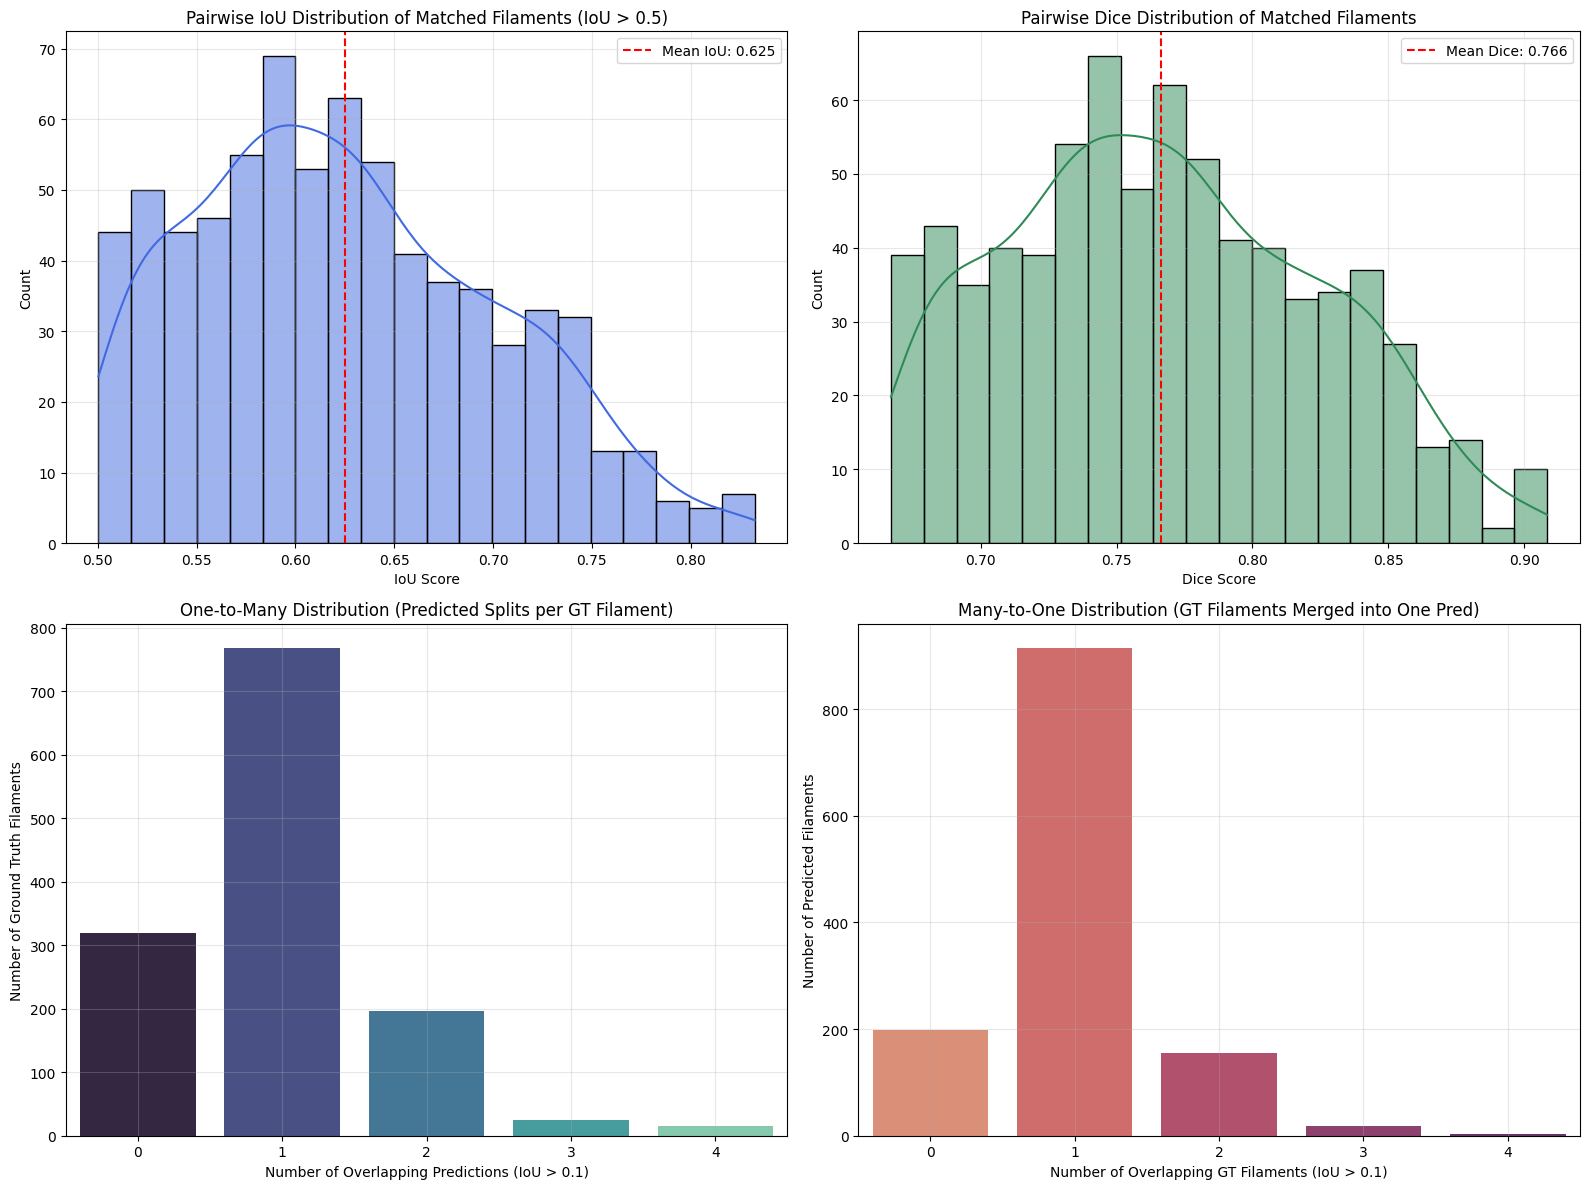

In [20]:
# Compute PQ Score on Validation Set
eval_results_v3 = get_pq_score(gt_df, pred_df)

print("\n=======================================================")
print("       🏆 OFFICIAL COMPETITION EVALUATION REPORT (v3)  ")
print("=======================================================")
print(f" Panoptic Quality  (PQ) : {eval_results_v3['PQ']:.4f}")
print(f" Segmentation Qual (SQ) : {eval_results_v3['SQ']:.4f}  (Mean IoU of True Matches)")
print(f" Recognition Qual  (RQ) : {eval_results_v3['RQ']:.4f}  (F1 Detection Score)")
print(f" True Positives    (TP) : {eval_results_v3['TP']}")
print(f" False Positives   (FP) : {eval_results_v3['FP']}")
print(f" False Negatives   (FN) : {eval_results_v3['FN']}")
print("=======================================================")

# Visual Distribution Graphs
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Pairwise IoU Score Distribution
sns.histplot(eval_results_v3["all_matched_ious"], bins=20, kde=True, ax=axes[0, 0], color="royalblue")
axes[0, 0].axvline(np.mean(eval_results_v3["all_matched_ious"]) if eval_results_v3["all_matched_ious"] else 0, color="red", linestyle="--", label=f"Mean IoU: {np.mean(eval_results_v3['all_matched_ious']):.3f}" if eval_results_v3['all_matched_ious'] else "")
axes[0, 0].set_title("Pairwise IoU Distribution of Matched Filaments (IoU > 0.5)", fontsize=12)
axes[0, 0].set_xlabel("IoU Score")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Pairwise Dice Score Distribution
sns.histplot(eval_results_v3["all_matched_dices"], bins=20, kde=True, ax=axes[0, 1], color="seagreen")
axes[0, 1].axvline(np.mean(eval_results_v3["all_matched_dices"]) if eval_results_v3["all_matched_dices"] else 0, color="red", linestyle="--", label=f"Mean Dice: {np.mean(eval_results_v3['all_matched_dices']):.3f}" if eval_results_v3['all_matched_dices'] else "")
axes[0, 1].set_title("Pairwise Dice Distribution of Matched Filaments", fontsize=12)
axes[0, 1].set_xlabel("Dice Score")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. One-to-Many Distribution (Filament Splitting)
sns.countplot(x=eval_results_v3["one_to_many_counts"], ax=axes[1, 0], palette="mako")
axes[1, 0].set_title("One-to-Many Distribution (Predicted Splits per GT Filament)", fontsize=12)
axes[1, 0].set_xlabel("Number of Overlapping Predictions (IoU > 0.1)")
axes[1, 0].set_ylabel("Number of Ground Truth Filaments")
axes[1, 0].grid(True, alpha=0.3)

# 4. Many-to-One Distribution (Filament Merging)
sns.countplot(x=eval_results_v3["many_to_one_counts"], ax=axes[1, 1], palette="flare")
axes[1, 1].set_title("Many-to-One Distribution (GT Filaments Merged into One Pred)", fontsize=12)
axes[1, 1].set_xlabel("Number of Overlapping GT Filaments (IoU > 0.1)")
axes[1, 1].set_ylabel("Number of Predicted Filaments")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()